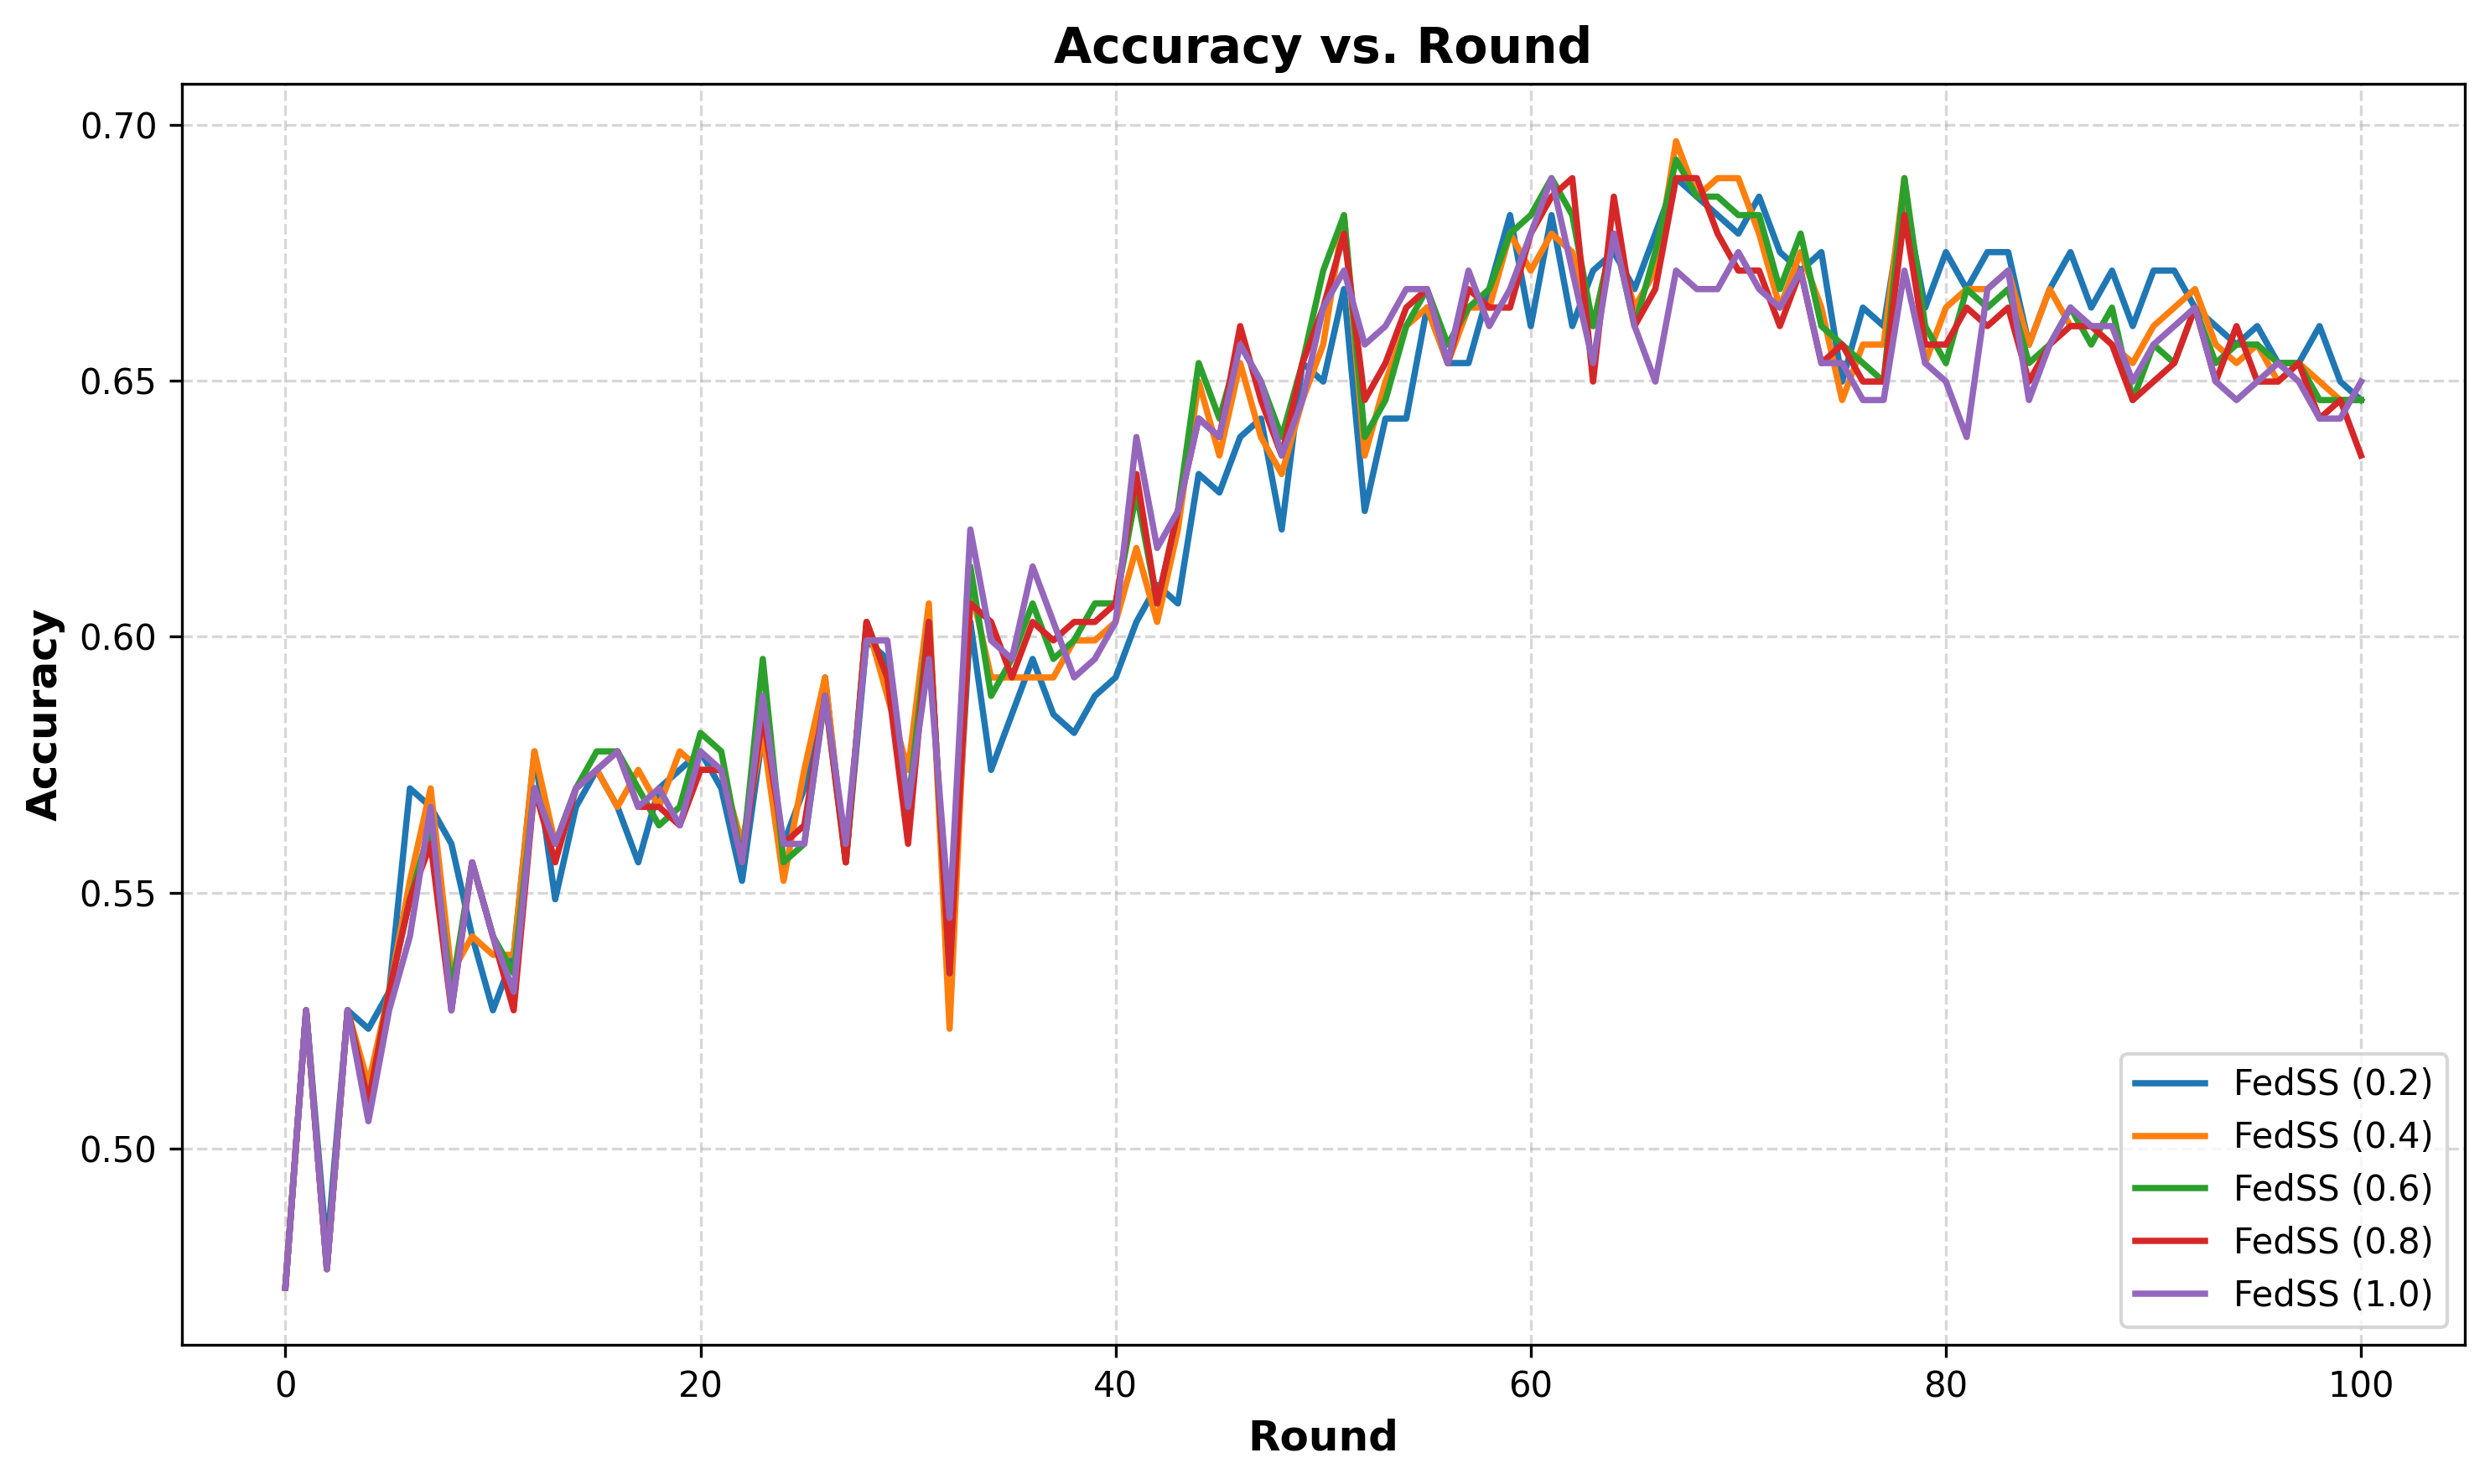

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# 定义要读取的7个 CSV 文件列表及其对应的图例标签
file_dict = {
    "rte_fedss_02.csv": "FedSS (0.2)",
    "rte_fedss_04.csv": "FedSS (0.4)",
    "rte_fedss_06.csv": "FedSS (0.6)",
    "rte_fedss_08.csv": "FedSS (0.8)",
    "rte_fedss_10.csv": "FedSS (1.0)",
#    "rte_rbla.csv": "RBLA",
#    "rte_zeropadding.csv": "Zero Padding",
}

# 创建画布
plt.figure(figsize=(10, 6), dpi=300)

# 循环读取各个文件并绘制曲线
for file_name, label in file_dict.items():
    try:
        # header=1 表示第二行是列名 (round, accuracy, ...)
        df = pd.read_csv(file_name, header=1)

        # 确保数据为数值类型并剔除空值
        df["round"] = pd.to_numeric(df["round"], errors="coerce")
        df["accuracy"] = pd.to_numeric(df["accuracy"], errors="coerce")
        df = df.dropna(subset=["round", "accuracy"])

        # 绘制折线图
        plt.plot(df["round"], df["accuracy"], label=label, linewidth=1.8)
    except FileNotFoundError:
        print(f"警告：未找到文件 {file_name}，已自动跳过。")

# 图表样式设置
plt.xlabel("Round", fontsize=12, fontweight="bold")
plt.ylabel("Accuracy", fontsize=12, fontweight="bold")
plt.title("Accuracy vs. Round", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)  # 网格线
plt.legend(loc="lower right", fontsize=10)  # 图例位置
plt.tight_layout()

# 显示图表或保存图片
plt.savefig("accuracy_vs_round.png", dpi=300)  # 保存图片
plt.show()  # 在 Jupyter Notebook 中直接展示

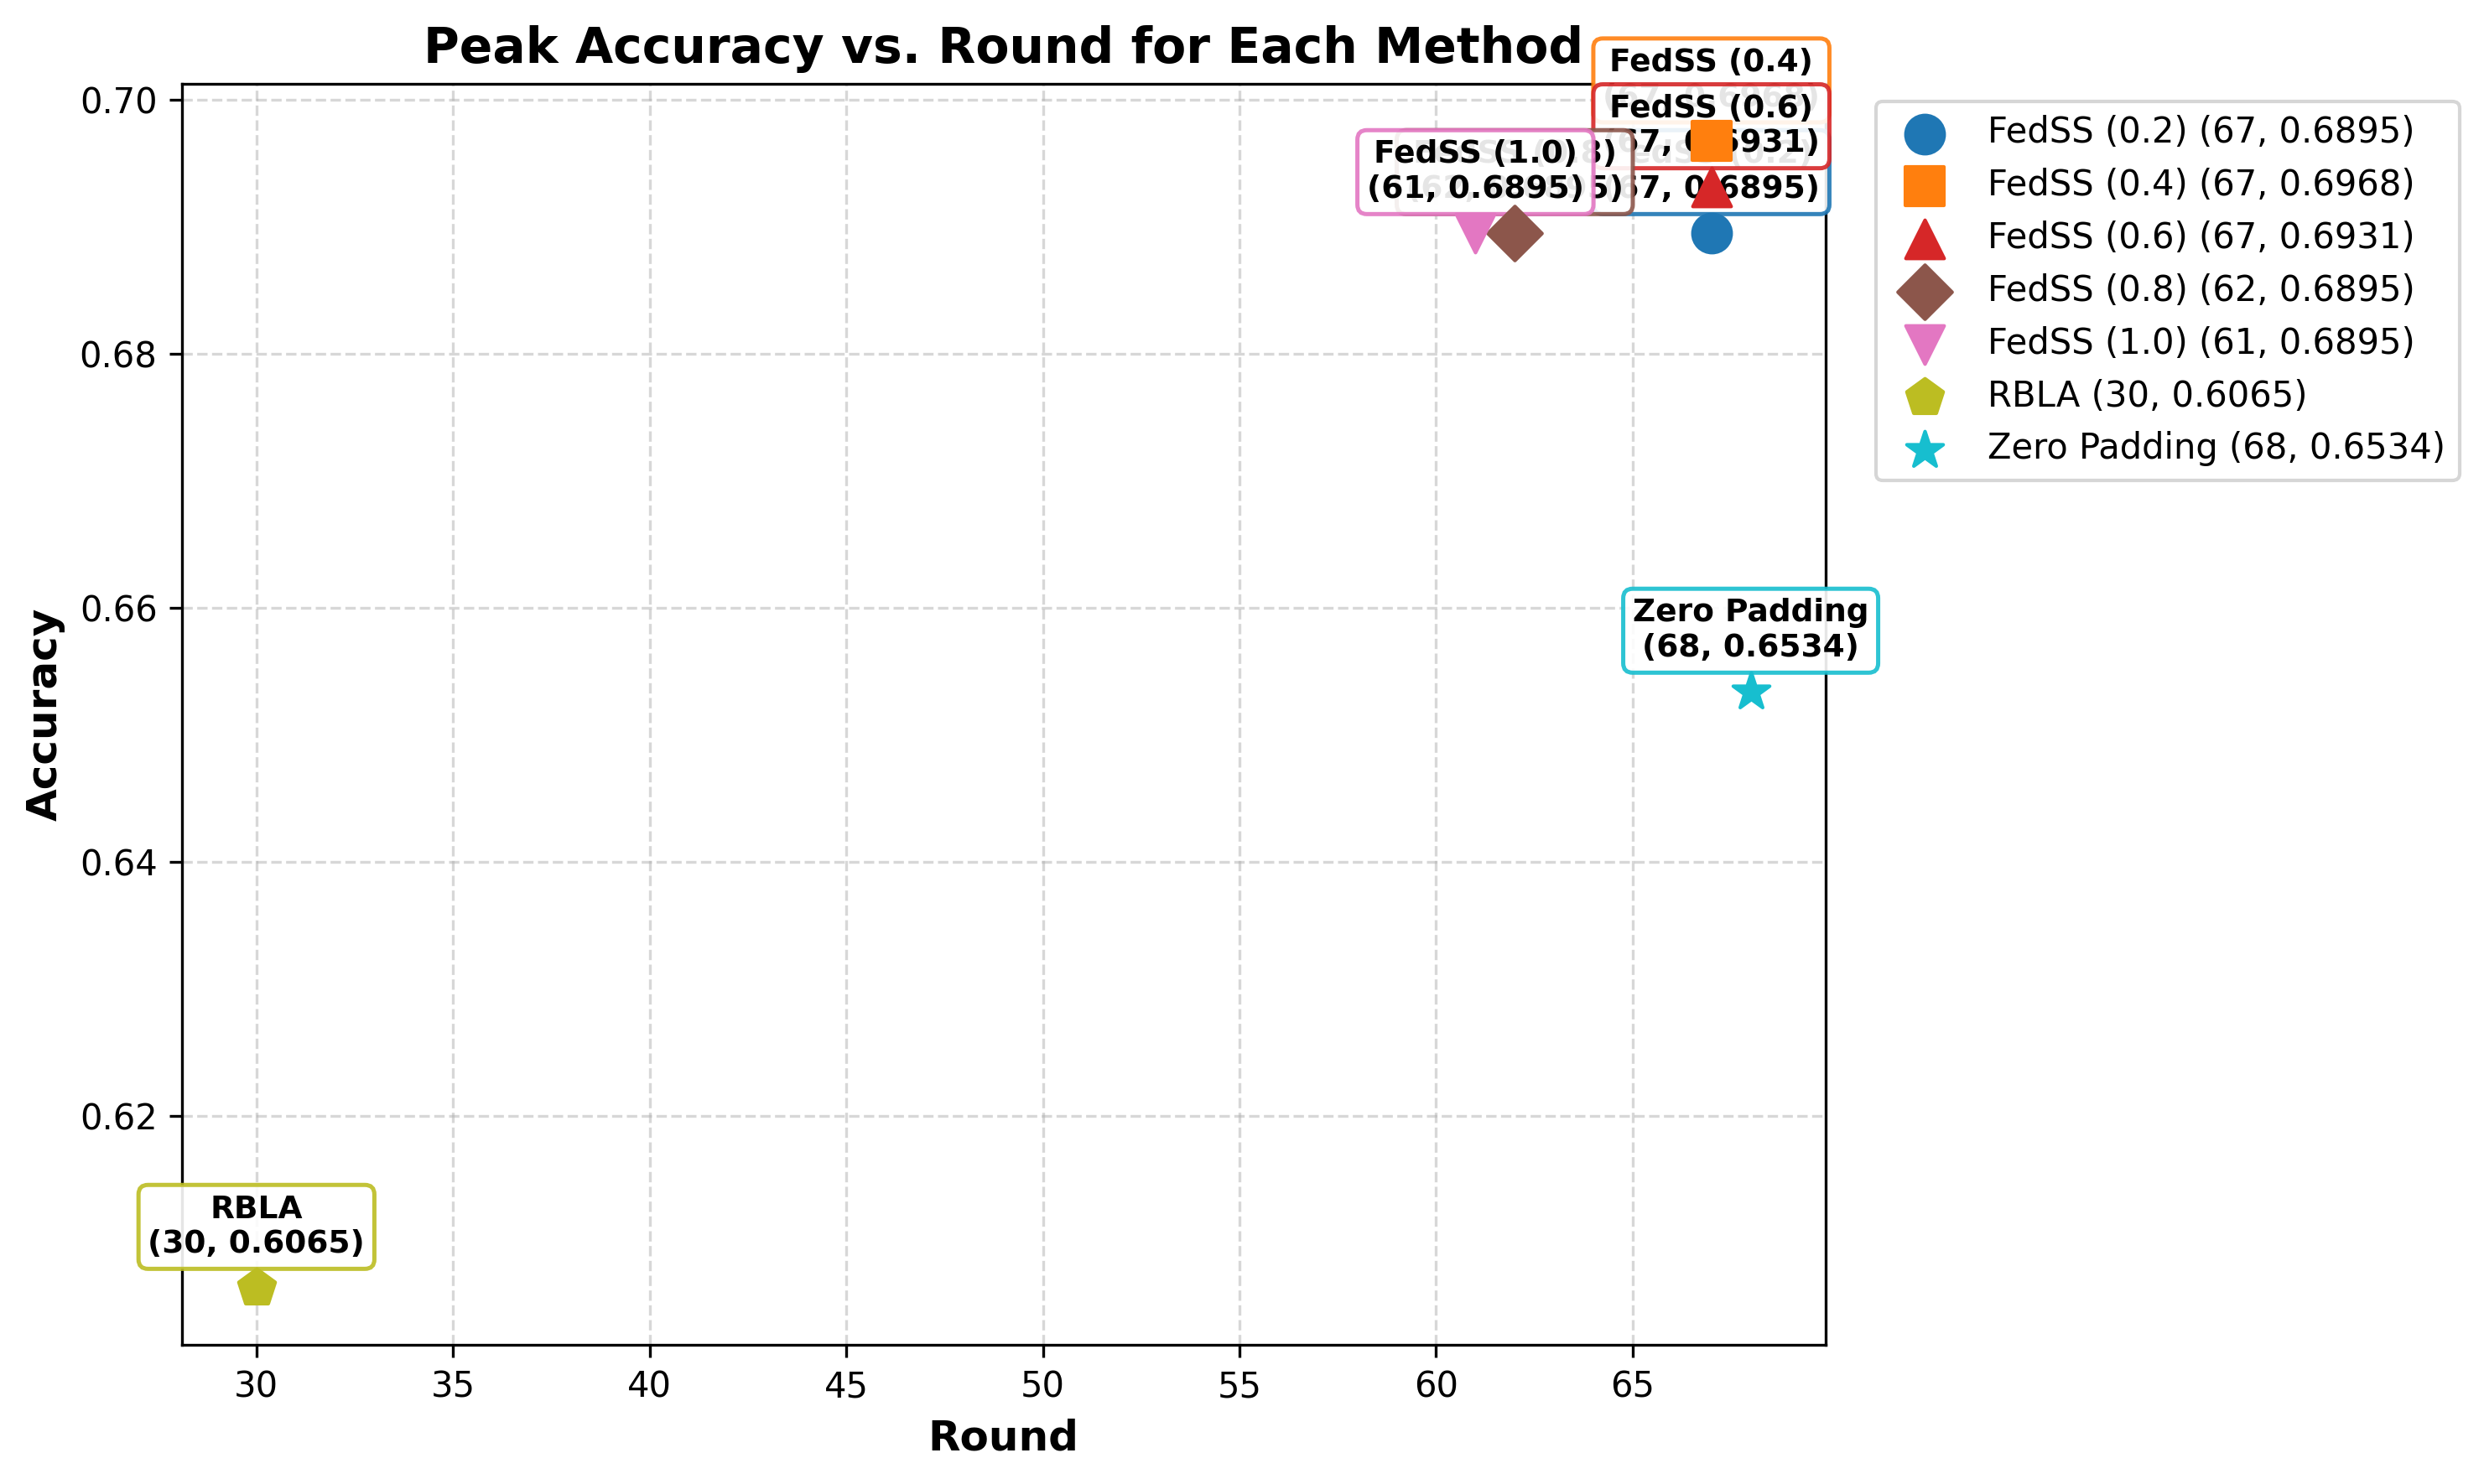

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

file_dict = {
    "rte_fedss_02.csv": "FedSS (0.2)",
    "rte_fedss_04.csv": "FedSS (0.4)",
    "rte_fedss_06.csv": "FedSS (0.6)",
    "rte_fedss_08.csv": "FedSS (0.8)",
    "rte_fedss_10.csv": "FedSS (1.0)",
    "rte_rbla.csv": "RBLA",
    "rte_zeropadding.csv": "Zero Padding",
}

max_points = []

# 提取每个 CSV 的最高精度及其对应 round
for file_name, label in file_dict.items():
    try:
        df = pd.read_csv(file_name, header=1)
        df["round"] = pd.to_numeric(df["round"], errors="coerce")
        df["accuracy"] = pd.to_numeric(df["accuracy"], errors="coerce")
        df = df.dropna(subset=["round", "accuracy"])

        # 找到精度最高的行
        max_idx = df["accuracy"].idxmax()
        best_round = int(df.loc[max_idx, "round"])
        best_acc = df.loc[max_idx, "accuracy"]

        max_points.append(
            {"label": label, "round": best_round, "accuracy": best_acc}
        )
    except FileNotFoundError:
        print(f"未找到文件 {file_name}，已跳过")

# 绘图
plt.figure(figsize=(10, 6), dpi=300)
colors = plt.cm.tab10(np.linspace(0, 1, len(max_points)))
markers = ["o", "s", "^", "D", "v", "p", "*"]

for i, p in enumerate(max_points):
    # 绘制最高点
    plt.scatter(
        p["round"],
        p["accuracy"],
        color=colors[i],
        marker=markers[i],
        s=120,
        zorder=5,
        label=f"{p['label']} ({p['round']}, {p['accuracy']:.4f})",
    )

    # 标注文本框
    plt.annotate(
        f"{p['label']}\n({p['round']}, {p['accuracy']:.4f})",
        (p["round"], p["accuracy"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3",
            fc="white",
            ec=colors[i],
            lw=1.2,
            alpha=0.9,
        ),
    )

plt.xlabel("Round", fontsize=12, fontweight="bold")
plt.ylabel("Accuracy", fontsize=12, fontweight="bold")
plt.title("Peak Accuracy vs. Round for Each Method", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
plt.tight_layout()

plt.savefig("peak_accuracy_scatter.png", dpi=300)
plt.show()

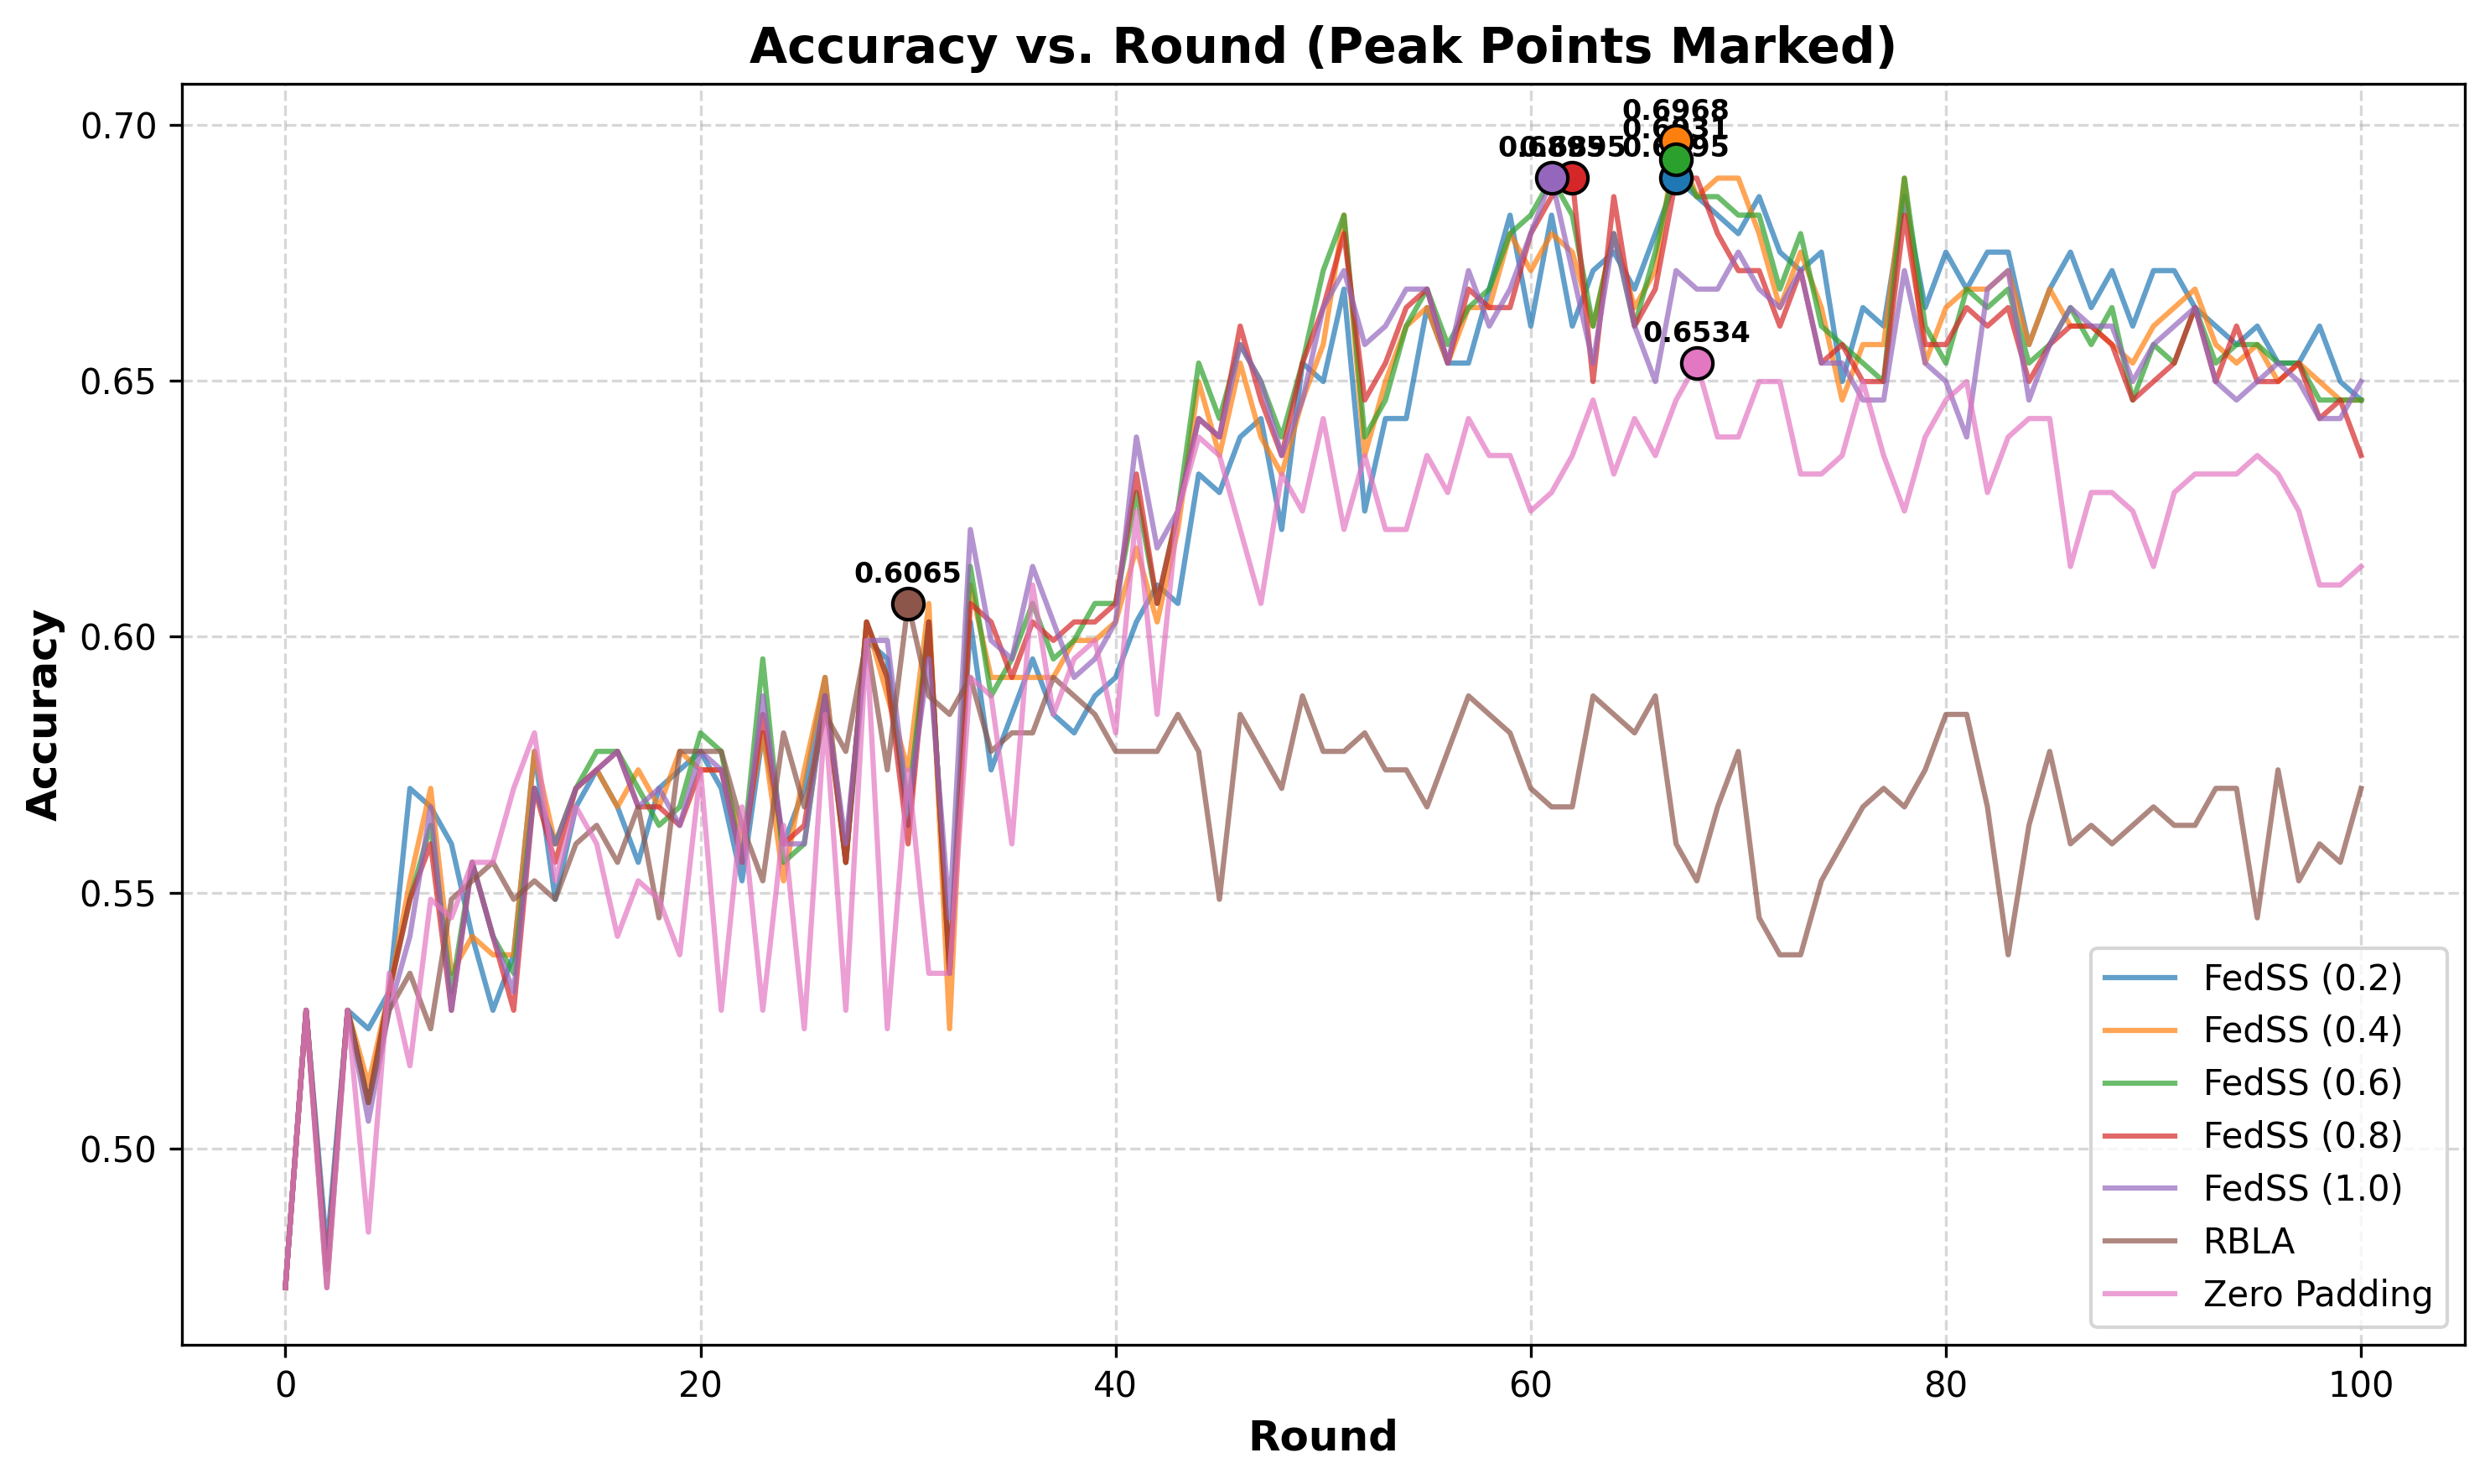

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

file_dict = {
    "rte_fedss_02.csv": "FedSS (0.2)",
    "rte_fedss_04.csv": "FedSS (0.4)",
    "rte_fedss_06.csv": "FedSS (0.6)",
    "rte_fedss_08.csv": "FedSS (0.8)",
    "rte_fedss_10.csv": "FedSS (1.0)",
    "rte_rbla.csv": "RBLA",
    "rte_zeropadding.csv": "Zero Padding",
}

plt.figure(figsize=(10, 6), dpi=300)

for file_name, label in file_dict.items():
    try:
        df = pd.read_csv(file_name, header=1)
        df["round"] = pd.to_numeric(df["round"], errors="coerce")
        df["accuracy"] = pd.to_numeric(df["accuracy"], errors="coerce")
        df = df.dropna(subset=["round", "accuracy"])

        # 绘制完整折线（无节点标记）
        (line,) = plt.plot(
            df["round"], df["accuracy"], label=label, linewidth=1.5, alpha=0.7
        )

        # 获取最高点
        max_idx = df["accuracy"].idxmax()
        best_round = df.loc[max_idx, "round"]
        best_acc = df.loc[max_idx, "accuracy"]

        # 只在最高点绘制红点/突出标记
        plt.scatter(
            best_round,
            best_acc,
            color=line.get_color(),
            s=80,
            zorder=5,
            edgecolors="black",
        )
        plt.annotate(
            f"{best_acc:.4f}",
            (best_round, best_acc),
            textcoords="offset points",
            xytext=(0, 6),
            ha="center",
            fontsize=8,
            fontweight="bold",
        )
    except FileNotFoundError:
        print(f"未找到文件 {file_name}，已跳过")

plt.xlabel("Round", fontsize=12, fontweight="bold")
plt.ylabel("Accuracy", fontsize=12, fontweight="bold")
plt.title(
    "Accuracy vs. Round (Peak Points Marked)", fontsize=14, fontweight="bold"
)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()

plt.savefig("accuracy_curves_with_peaks.png", dpi=300)
plt.show()